# 20 Netzvergleich und Wintervergleich

- Der Kennlinien-Monitor (Notebook 14) misst jede Station nur an ihrer eigenen Geschichte; eine Station mit dauerhaft schlechtem Normalbetrieb fällt ihm nie auf.
- Der alte Vorher/Nachher-Vergleich stellt Spätsommer und Herbst nebeneinander (50 der 58 Begehungen zwischen August und November 2024), also Jahreszeiten mit sehr unterschiedlichem Wärmebedarf.
- Teil A: Normalbetrieb jeder Station im Kernwinter (Dezember bis Februar) gegen die übrigen Stationen desselben Winters. Teil B: je Begehung Kernwinter davor gegen Kernwinter danach, mit Kontrollgruppe.
- Logik in `src/netzvergleich.py` und `src/kennlinien_monitor.py` (`wintervergleich`), Doku in `docs/kennlinien-monitor.md`.

In [1]:
import sys
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

from src import befundcodes as bc
from src import kennlinien_monitor as km
from src import load_begehungen as lb
from src import load_data as ld
from src import netzvergleich as nv
from src import stationsbilder as sb
from src import ternaer as tn
from src import weather

pd.set_option("display.width", 170)
pd.set_option("display.max_columns", 30)

METER_DIR = ROOT / "data" / "processed" / "real_meters"
ZUORDNUNG_PATH = ROOT / "data" / "raw" / "Zuordnung.xlsx"
BEISPIEL = 68956351

t0 = time.time()
serien = tn.lade_serien(METER_DIR)
termine = {int(k): list(v) for k, v in lb.begehung_dates_by_meter().items()}
#Begehungen ohne Datum: begangen, aber zeitlich nicht zuzuordnen (wie NB 16).
#Sie fehlen in der Kontrollgruppe und zählen im Profil als begangen.
beg_alle = lb.begehungen_mit_zaehler()
datiert = {m for m, d in termine.items() if d}
ohne_datum = set(beg_alle["meter"].dropna().astype(int)) - datiert

nodes = ld.load_logical_nodes()
aw_tab = pd.DataFrame({
    "meter": pd.to_numeric(nodes["Zählernummer"], errors="coerce"),
    "kw": pd.to_numeric(nodes["Anschlusswert"], errors="coerce")}).dropna()
anschlusswerte = aw_tab.groupby(aw_tab["meter"].astype(int))["kw"].max().to_dict()

vpin = pd.concat([pd.read_excel(ZUORDNUNG_PATH, sheet_name=s, dtype={"V-PIN": str})
                  [["Zählernummer", "V-PIN"]] for s in ("2024", "2025")])
vpin["Zählernummer"] = pd.to_numeric(vpin["Zählernummer"], errors="coerce")
bhkw = set(vpin.loc[vpin["V-PIN"] == "BHKW", "Zählernummer"].dropna().astype(int))

#Punkttabellen einmal rechnen, Netz- und Wintervergleich nutzen dieselben
punkte = {int(m): sb.punkttabelle(df, int(m), "stunde") for m, df in serien.items()}
print(f"{len(serien)} Zählerreihen, {len(datiert)} Zähler mit datierter Begehung, "
      f"{len(ohne_datum)} mit Begehung ohne Datum, "
      f"{len(anschlusswerte)} mit Anschlusswert, BHKW: {sorted(bhkw)}, "
      f"{time.time() - t0:.0f} s")

100 Zählerreihen, 56 Zähler mit datierter Begehung, 6 mit Begehung ohne Datum, 99 mit Anschlusswert, BHKW: [86792512], 18 s


## A1 Kennzahlen je Station und Kernwinter

- Nur Betriebsstunden, ohne die 7 Tage vor und nach einer Begehung.
- Unter 300 Betriebsstunden keine Zeile. Winter 21/22 hat nur Tageswerte und fällt komplett heraus.

In [2]:
tabelle, ausschluss = nv.winterkennzahlen(punkte, anschlusswerte, termine)
print("Stationen je Winter:")
display(tabelle.groupby("winter").size().to_frame("Stationen"))
print("Ausschlüsse:")
display(ausschluss.groupby(["winter", "grund"]).size().to_frame("Anzahl"))

Stationen je Winter:


,Stationen
winter,
22/23,41
23/24,85
24/25,85
25/26,4


Ausschlüsse:


,,Anzahl
winter,grund,
,keine_daten,6
21/22,zu_wenig_stunden,43
22/23,zu_wenig_stunden,2
23/24,zu_wenig_stunden,2
24/25,zu_wenig_stunden,3


## A2 Netzbezug, Redundanz und Score

- Jede Kennzahl wird gegen Median und MAD der Stationen desselben Winters standardisiert (z-Wert), positiv heißt schlechter.
- Das BHKW bekommt Werte, bestimmt die Referenz aber nicht mit. Unter 20 Referenzstationen gibt es keine z-Werte.
- Vorab geprüft, ob spezifischer Volumenstrom und Referenzspreizung so eng zusammenhängen, dass sie im Score doppelt zählen.

In [3]:
bezogen = nv.netzbezug(tabelle, referenz_ausschluss=tuple(bhkw) or nv.REFERENZ_AUSSCHLUSS)
kz, rho = nv.score_kennzahlen(bezogen)
display(rho.round(3))
print("Kennzahlen im Score:", list(kz))
markiert = nv.markiere(bezogen, kz)
print(markiert.groupby("winter").agg(stationen=("meter", "size"),
                                     bezug=("bezug", "first"),
                                     auffaellig=("auffaellig", "sum")))

,winter,rho,n
0,22/23,-0.760,37
1,23/24,-0.675,80
2,24/25,-0.740,80
3,25/26,NaN,4


Kennzahlen im Score: ['spreizung_ref_k', 'steigung', 'residuum_sd', 'rl_ueber_50_anteil', 'flow_spez_lh_kw']
        stationen     bezug  auffaellig
winter                                 
22/23          41      netz           6
23/24          85      netz           9
24/25          85      netz          13
25/26           4  zu_klein           0


In [4]:
z_spalten = [f"z_{k}" for k in kz]
for w in ("23/24", "24/25"):
    top = (markiert[markiert["winter"] == w].sort_values("rang")
           [["meter", "rang", "score", "n_kennzahlen", "n_schlecht", "auffaellig", "in_referenz"] + z_spalten]
           .head(10))
    print(f"Schlechteste zehn im Winter {w}:")
    display(top.round(2))

Schlechteste zehn im Winter 23/24:


,meter,rang,score,n_kennzahlen,n_schlecht,auffaellig,in_referenz,z_spreizung_ref_k,z_steigung,z_residuum_sd,z_rl_ueber_50_anteil,z_flow_spez_lh_kw
53,68956351,1.0,3.30,5,4,True,True,2.71,3.52,0.42,1.64,8.23
84,72167777,2.0,2.56,5,4,True,True,2.51,3.47,-1.15,1.66,6.31
86,72167782,3.0,2.47,5,4,True,True,2.41,2.96,-0.65,1.59,6.06
66,68956372,4.0,2.42,5,4,True,True,2.54,3.26,-1.20,1.55,5.93
80,72135480,5.0,2.17,5,3,True,True,2.68,3.48,-0.37,1.67,3.36
112,80912182,6.0,2.06,5,2,True,True,2.18,3.21,0.00,1.55,3.36
76,72135453,7.0,1.93,5,3,True,True,1.86,1.41,-0.39,1.65,5.13
74,72135442,8.0,1.84,5,1,False,True,1.35,1.43,4.72,0.82,0.85
90,72167793,9.0,1.49,5,2,True,True,1.65,3.11,0.74,1.28,0.69
57,68956356,10.0,1.43,5,1,False,True,1.28,-0.67,3.23,1.07,2.26


Schlechteste zehn im Winter 24/25:


,meter,rang,score,n_kennzahlen,n_schlecht,auffaellig,in_referenz,z_spreizung_ref_k,z_steigung,z_residuum_sd,z_rl_ueber_50_anteil,z_flow_spez_lh_kw
191,80912182,1.0,2.05,5,4,True,True,2.30,3.50,-0.06,1.91,2.57
184,80912173,2.0,2.04,5,4,True,True,2.11,3.51,-0.01,1.84,2.72
155,72135442,3.0,1.94,5,2,True,True,1.32,1.46,2.98,1.16,2.76
170,72167793,4.0,1.87,5,3,True,True,2.41,3.65,-0.37,1.93,1.73
131,68956344,5.0,1.83,5,1,False,True,1.54,0.50,4.26,0.99,1.88
156,72135453,6.0,1.75,5,3,True,True,1.82,1.65,-0.22,1.93,3.57
207,80956410,7.0,1.74,5,3,True,True,1.88,-1.62,2.86,1.57,4.01
160,72135480,8.0,1.52,5,3,True,True,2.18,1.93,-0.21,1.96,1.72
139,68956356,9.0,1.48,5,1,False,True,1.49,2.02,0.80,1.78,1.31
149,68956373,10.0,1.46,5,3,True,True,1.61,-0.80,2.71,1.60,2.20


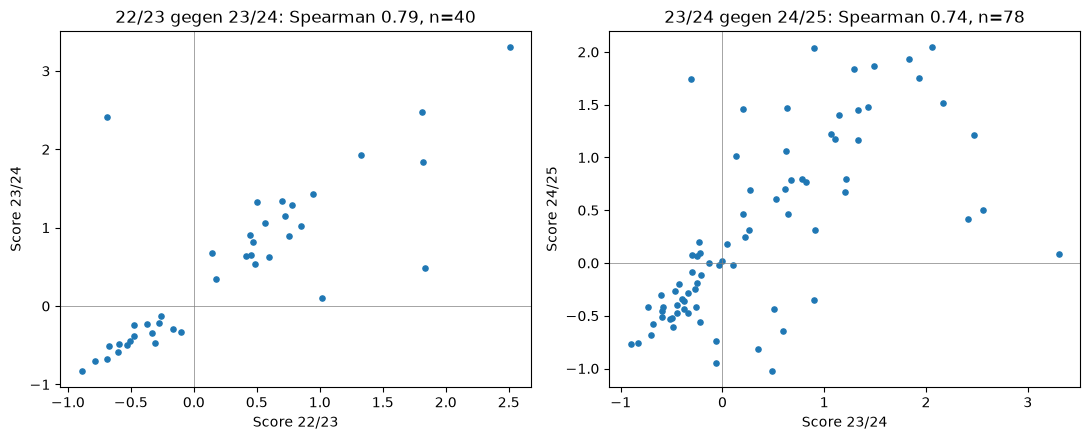

In [5]:
#Hält der Rang über die Winter? Wenn nicht, misst der Score eher den Winter als die Station.
breit = markiert.pivot_table(index="meter", columns="winter", values="score")
paare = [("22/23", "23/24"), ("23/24", "24/25")]
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, (a, b) in zip(axes, paare):
    teil = breit[[a, b]].dropna()
    rho_ab = teil.corr(method="spearman").iloc[0, 1]
    ax.scatter(teil[a], teil[b], s=14)
    ax.axhline(0, color="grey", lw=0.5)
    ax.axvline(0, color="grey", lw=0.5)
    ax.set_xlabel(f"Score {a}")
    ax.set_ylabel(f"Score {b}")
    ax.set_title(f"{a} gegen {b}: Spearman {rho_ab:.2f}, n={len(teil)}")
plt.tight_layout()
plt.show()

## A3 Chronisch auffällige Stationen

- Auffällig in einem Winter: mindestens zwei Kennzahlen im schlechtesten Zehntel der Referenz.
- Chronisch: in mindestens zwei Wintern auffällig.

In [6]:
uebersicht = nv.stationsuebersicht(markiert)
uebersicht["je_auffaellig"] = uebersicht["n_auffaellig"] >= 1
print(f"{int(uebersicht['chronisch'].sum())} chronisch, "
      f"{int(uebersicht['je_auffaellig'].sum())} mindestens einmal auffällig, "
      f"von {len(uebersicht)} Stationen mit Score")
display(uebersicht[uebersicht["je_auffaellig"]].round(2))

8 chronisch, 18 mindestens einmal auffällig, von 93 Stationen mit Score


,meter,n_winter,n_auffaellig,score_median,rang_median,in_referenz,winter_auffaellig,chronisch,je_auffaellig
0,68956351,3,2,2.51,1.0,True,"22/23,23/24",True,True
1,80912182,2,2,2.05,3.5,True,"23/24,24/25",True,True
2,72135480,2,2,1.84,6.5,True,"23/24,24/25",True,True
3,72135442,3,2,1.84,3.0,True,"22/23,24/25",True,True
4,72167782,3,3,1.81,4.0,True,"22/23,23/24,24/25",True,True
5,72135453,3,3,1.75,6.0,True,"22/23,23/24,24/25",True,True
6,72167793,2,2,1.68,6.5,True,"23/24,24/25",True,True
7,72167777,2,1,1.53,16.0,True,23/24,False,True
8,80912173,2,1,1.47,11.5,True,24/25,False,True
10,68956360,3,2,1.33,12.0,True,"23/24,24/25",True,True


In [7]:
#Sensitivität: Vergleich nur innerhalb der Leistungsklasse
klasse = nv.markiere(nv.netzbezug(tabelle, gruppe="leistungsklasse",
                                  referenz_ausschluss=tuple(bhkw) or nv.REFERENZ_AUSSCHLUSS), kz)
ue_kl = nv.stationsuebersicht(klasse)
a = set(uebersicht.loc[uebersicht["chronisch"], "meter"])
b = set(ue_kl.loc[ue_kl["chronisch"], "meter"])
jacc = len(a & b) / len(a | b) if a | b else np.nan
print(f"chronisch Netzbezug {len(a)}, Klassenbezug {len(b)}, gemeinsam {len(a & b)}, Jaccard {jacc:.2f}")
print("Bezug je Winter und Klasse:")
display(klasse.groupby(["winter", "bezug"]).size().unstack(fill_value=0))

chronisch Netzbezug 8, Klassenbezug 8, gemeinsam 8, Jaccard 1.00
Bezug je Winter und Klasse:


bezug,leistungsklasse,netz,zu_klein
winter,,,
22/23,37,4,0
23/24,79,6,0
24/25,80,5,0
25/26,0,0,4


## A4 Was haben die auffälligen Stationen gemeinsam?

- Bool- und kategoriale Merkmale mit Fishers exaktem Test, numerische mit Mann-Whitney. Bei rund 85 Stationen und vielen Merkmalen ist ein kleiner p-Wert nur ein Hinweis.
- Befundcodes fehlen bei Stationen ohne Begehung. Begehungen ohne Datum zählen als begangen.

In [8]:
labels = bc.labels_je_zaehler(bc.kodiere_begehungen())
kontext = nv.kontext_tabelle(uebersicht["meter"], anschlusswerte, bhkw, termine, labels,
                             begangen_ohne_datum=ohne_datum)
chron = kontext[kontext["meter"].isin(uebersicht.loc[uebersicht["chronisch"], "meter"])]
print("Chronische Stationen und Begehungen:")
display(chron[["meter", "hat_begehung", "n_begehungen"]])
print("Chronisch und nie begangen:",
      sorted(chron.loc[~chron["hat_begehung"], "meter"].tolist()))
for gruppe in ("chronisch", "je_auffaellig"):
    n = int(uebersicht[gruppe].sum())
    print(f"Profil für '{gruppe}' (n={n}):")
    if n < 3:
        print("  zu wenige Stationen für ein Profil")
        continue
    display(nv.profil(uebersicht, kontext, gruppe=gruppe).head(12).round(3))

Chronische Stationen und Begehungen:


,meter,hat_begehung,n_begehungen
13,68956351,True,1
19,68956360,False,0
34,72135442,True,1
36,72135453,False,0
40,72135480,False,0
46,72167782,True,0
50,72167793,False,0
73,80912182,True,1


Chronisch und nie begangen: [68956360, 72135453, 72135480, 72167793]
Profil für 'chronisch' (n=8):


,merkmal,auspraegung,test,n_gruppe,n_rest,wert_gruppe,wert_rest,p_wert
0,ventil_stellantrieb,,fisher,4,52,1.00,0.096,0.000
1,n_befunde,,mannwhitney,4,52,1.50,0.500,0.026
2,daemmung,,fisher,4,52,0.25,0.058,0.263
3,pumpe,,fisher,4,52,0.25,0.058,0.263
4,n_begehungen,,mannwhitney,8,84,0.00,1.000,0.276
5,schmutzfaenger,,fisher,4,52,0.25,0.096,0.373
6,anschlusswert_kw,,mannwhitney,8,77,12.00,10.000,0.381
7,regler_parameter,,fisher,4,52,0.25,0.115,0.423
8,leistungsklasse,über 10 kW,fisher,8,84,0.50,0.333,0.442
9,fussbodenheizung,,fisher,4,52,0.50,0.327,0.598


Profil für 'je_auffaellig' (n=18):


,merkmal,auspraegung,test,n_gruppe,n_rest,wert_gruppe,wert_rest,p_wert
0,ventil_stellantrieb,,fisher,10,46,0.400,0.109,0.044
1,pumpe,,fisher,10,46,0.200,0.043,0.142
2,daemmung,,fisher,10,46,0.200,0.043,0.142
3,n_befunde,,mannwhitney,10,46,1.000,1.000,0.228
4,anschlusswert_kw,,mannwhitney,16,69,11.500,10.000,0.254
5,leistungsklasse,5-10 kW,fisher,18,74,0.444,0.595,0.295
6,leistungsklasse,über 10 kW,fisher,18,74,0.444,0.324,0.411
7,anlage_aus,,fisher,10,46,0.100,0.043,0.452
8,naturumlauf,,fisher,10,46,0.100,0.043,0.452
9,n_begehungen,,mannwhitney,18,74,0.500,1.000,0.546


## B1 Kernwinter vor gegen Kernwinter nach der Begehung

- Jüngster Kernwinter mit genug Stunden vor dem Termin gegen frühesten danach, je 7 Tage Abstand.
- Volumenstrom: Median vorher und nachher in l/h und der Durchfluss, den beide Kennlinien bei derselben Leistung vorhersagen.
- Kreuzresiduum: wie weit die Stunden des Nachwinters unter oder über der Kennlinie des Vorwinters liegen.

In [9]:
try:
    temp = weather.load_outdoor_temperature("2022-11-01", "2026-03-01", allow_download=False)
    hgs = nv.heizgradstunden_je_winter(temp)
    display(hgs.round(0))
except Exception as fehler:
    print("Keine Außentemperatur verfügbar:", fehler)
    hgs = None

vergleich = km.wintervergleich(punkte, termine, anschlusswerte, markiert, hgs)
print(vergleich["status"].value_counts().to_string())
print("Termin im Kernwinter je Status:")
print(vergleich.groupby("status")["termin_im_winter"].sum().astype(int).to_string())
print("Ohne Nachwinter:")
print(vergleich.loc[vergleich["status"] == "kein_nachwinter", ["meter", "datum"]]
      .assign(datum=lambda d: d["datum"].dt.date).to_string(index=False))
ok = vergleich[vergleich["status"] == "ok"]
print("Winterpaare:")
display(ok.groupby(["winter_vor", "winter_nach"]).size().to_frame("Begehungen"))

,winter,heizgradstunden,n_stunden
0,22/23,25011.0,2160
1,23/24,22619.0,2184
2,24/25,27366.0,2160
3,25/26,27174.0,2160


status
ok                 42
kein_nachwinter     6
keine_daten         5
kein_vorwinter      3
zu_wenig_punkte     2
Termin im Kernwinter je Status:
status
kein_nachwinter    0
kein_vorwinter     0
keine_daten        0
ok                 0
zu_wenig_punkte    1
Ohne Nachwinter:
   meter      datum
68956367 2025-09-12
68956373 2025-03-12
72135441 2024-10-14
72135486 2025-09-13
72167783 2025-09-11
80912165 2024-09-09
Winterpaare:


,,Begehungen
winter_vor,winter_nach,
23/24,24/25,41
24/25,25/26,1


In [10]:
spalten = ["meter", "datum", "winter_vor", "winter_nach",
           "flow_median_lh_vor", "flow_median_lh_nach", "d_flow_median_lh",
           "flow_verhaeltnis", "flow_bei_pref_vor", "flow_bei_pref_nach",
           "d_steigung", "d_spreizung_ref_k", "residuum_kreuz",
           "rang_vor", "rang_nach", "weitere_begehung"]
tabelle_b1 = ok[spalten].assign(datum=ok["datum"].dt.date)
display(tabelle_b1.sort_values("d_flow_median_lh").round(2))
print(f"Gegenprobe {BEISPIEL} (Ventilreparatur Sep. 2024):")
display(tabelle_b1[tabelle_b1["meter"] == BEISPIEL].round(3).T)

,meter,datum,winter_vor,winter_nach,flow_median_lh_vor,flow_median_lh_nach,d_flow_median_lh,flow_verhaeltnis,flow_bei_pref_vor,flow_bei_pref_nach,d_steigung,d_spreizung_ref_k,residuum_kreuz,rang_vor,rang_nach,weitere_begehung
6,68956351,2024-09-09,23/24,24/25,567.0,103.0,-464.0,0.18,518.07,58.68,1.38,21.60,-1.53,1.0,41.0,False
16,68956372,2024-10-14,23/24,24/25,329.0,131.0,-198.0,0.40,328.80,99.45,0.66,13.43,-0.91,4.0,33.0,False
5,68956348,2024-09-09,23/24,24/25,809.0,703.0,-106.0,0.87,803.64,784.11,0.05,0.19,-0.05,14.0,21.0,False
52,80912193,2024-11-05,23/24,24/25,233.0,169.0,-64.0,0.73,223.42,175.69,-0.11,7.29,-0.22,48.0,79.0,False
30,80912154,2024-09-23,23/24,24/25,217.0,189.0,-28.0,0.87,222.60,151.63,0.07,9.86,-0.42,34.0,67.0,False
37,80912164,2024-08-26,23/24,24/25,90.0,68.0,-22.0,0.76,88.91,92.97,-0.13,-3.53,0.04,56.0,43.0,False
32,80912159,2024-09-10,23/24,24/25,159.0,141.0,-18.0,0.89,154.08,156.03,-0.06,-0.25,-0.00,75.0,73.0,False
10,68956356,2024-09-19,23/24,24/25,233.0,216.0,-17.0,0.93,181.26,198.10,-0.73,-1.64,0.19,10.0,9.0,False
46,80912180,2024-09-20,23/24,24/25,117.0,111.0,-6.0,0.95,120.63,114.99,-0.22,1.51,-0.10,77.0,65.0,False
54,80912196,2024-10-10,23/24,24/25,155.0,151.0,-4.0,0.97,144.42,147.03,0.24,-0.51,-0.15,67.0,58.0,False


Gegenprobe 68956351 (Ventilreparatur Sep. 2024):


,6
meter,68956351
datum,2024-09-09
winter_vor,23/24
winter_nach,24/25
flow_median_lh_vor,567.0
flow_median_lh_nach,103.0
d_flow_median_lh,-464.0
flow_verhaeltnis,0.182
flow_bei_pref_vor,518.074
flow_bei_pref_nach,58.682


## B2 Begehungsfälle gegen Stationen ohne Begehung

- Kontrollgruppe: Stationen ohne Begehung mit den Wintern 23/24 und 24/25, ohne Stationen mit Begehung ohne Datum.
- Nur Begehungsfälle mit genau diesem Winterpaar, jede Station einmal.

Kontrollgruppe 29 Stationen, ohne Datum ausgeschlossen: [65273846, 68956347, 72135481, 72167782, 80912202]


,spalte,n_begehung,median_begehung,n_kontrolle,median_kontrolle,p_mw
0,d_steigung,40,0.011,29,-0.010,0.927
1,d_spreizung_ref_k,40,0.662,29,-0.524,0.346
2,d_residuum_sd,40,-0.003,29,-0.001,0.640
3,d_rl_ueber_50_anteil,40,-0.020,29,0.000,0.183
4,d_flow_median_lh,40,14.500,29,15.000,0.961
5,flow_verhaeltnis,40,1.081,29,1.154,0.738
6,d_flow_spez_lh_kw,39,1.250,27,1.154,0.984
7,residuum_kreuz,40,-0.048,29,0.000,0.391


41 Begehungen an 40 Stationen mit dem Paar 23/24 gegen 24/25


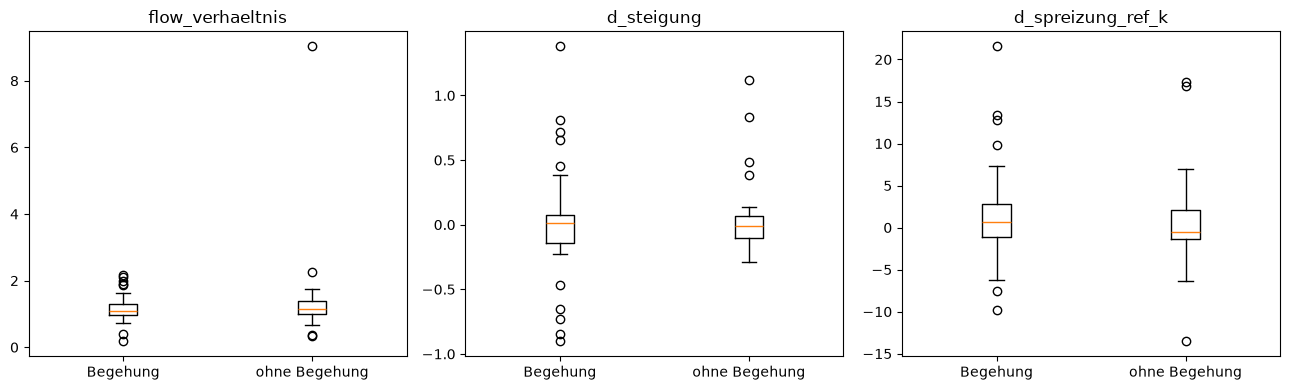

In [11]:
kontrolle = km.winterdifferenz_kontrolle(tabelle, termine, punkte=punkte, ausschluss=ohne_datum)
print(f"Kontrollgruppe {len(kontrolle)} Stationen, "
      f"ohne Datum ausgeschlossen: {sorted(ohne_datum & set(tabelle['meter'].astype(int)))}")
gv = km.gruppenvergleich(vergleich, kontrolle)
display(gv.round(3))

fig, axes = plt.subplots(1, 3, figsize=(13, 4))
paar_alle = ok[(ok["winter_vor"] == "23/24") & (ok["winter_nach"] == "24/25")]
paar = (paar_alle.sort_values(["meter", "datum"])
        .drop_duplicates(["meter", "winter_vor", "winter_nach"]))
print(f"{len(paar_alle)} Begehungen an {len(paar)} Stationen mit dem Paar 23/24 gegen 24/25")
for ax, s in zip(axes, ("flow_verhaeltnis", "d_steigung", "d_spreizung_ref_k")):
    ax.boxplot([paar[s].dropna(), kontrolle[s].dropna()])
    ax.set_xticks([1, 2], ["Begehung", "ohne Begehung"])
    ax.set_title(s)
plt.tight_layout()
plt.show()

In [12]:
#Wechsel der Netzauffälligkeit über die Begehung, jede Station einmal
wechsel = paar.dropna(subset=["auffaellig_vor", "auffaellig_nach"])
display(pd.crosstab(wechsel["auffaellig_vor"].map({True: "auffällig vorher", False: "unauffällig vorher"}),
                    wechsel["auffaellig_nach"].map({True: "auffällig nachher", False: "unauffällig nachher"})))

auffaellig_nach,auffällig nachher,unauffällig nachher
auffaellig_vor,,
auffällig vorher,1,2
unauffällig vorher,3,34


## C Stationsblatt je Station

- `src/stationsblatt.py` zeigt je Station Steigung und Spreizung aus dem gleitenden Fenster des Monitors vor dem Netzband (10. bis 90. Perzentil aller Stationen am selben Tag, ohne BHKW), darunter Kennlinie je Kernwinter und Netz-z-Werte.
- Export aller Bilder mit `python -m src.stationsblatt` (einige Minuten), hier nur das Beispiel.

100 Statuszeilen, 93 mit Netzwert, 109 s


grund
                    93
keine_daten          6
zu_wenig_stunden     1

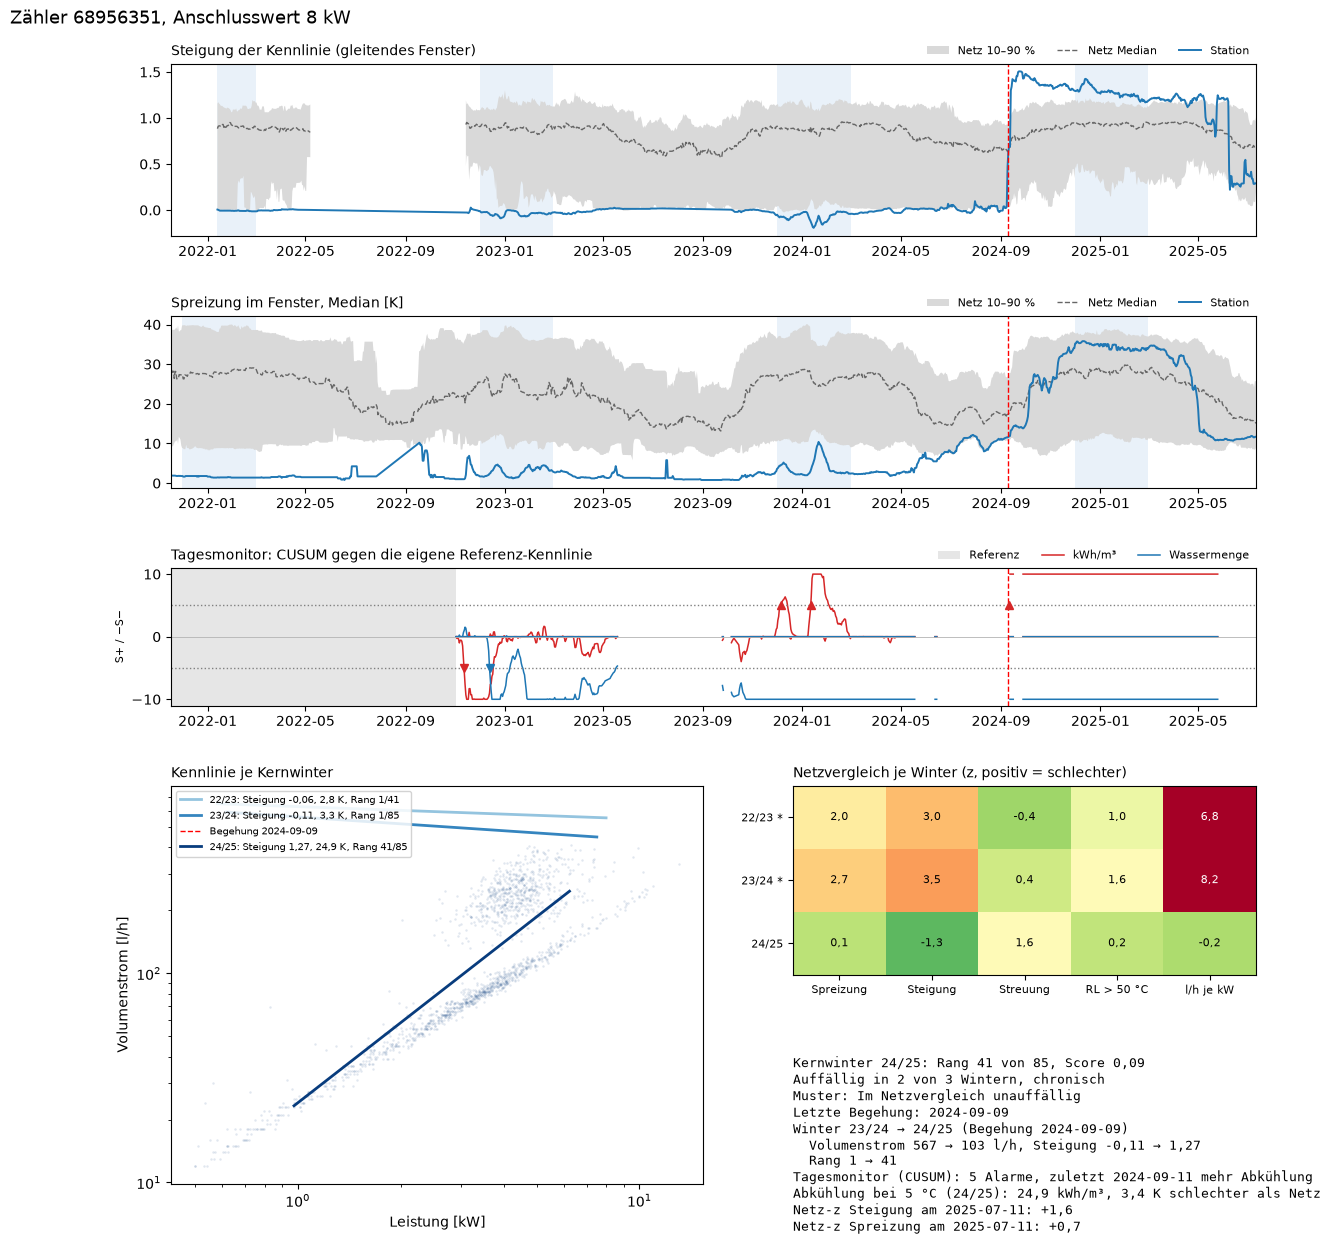

In [13]:
from src import stationsblatt as bl

t0 = time.time()
blatt = bl.rechne(serien, termine, anschlusswerte, bhkw, ohne_datum)
status = bl.statustabelle(blatt)
print(f"{len(status)} Statuszeilen, {status['score'].notna().sum()} mit Netzwert, "
      f"{time.time() - t0:.0f} s")
display(status["grund"].value_counts())
fig = bl.zeichne_stationsblatt(BEISPIEL, blatt, status[status["meter"] == BEISPIEL].iloc[0])
plt.show()

In [14]:
spalten = ["meter", "winter", "rang", "n_stationen", "auffaellig", "chronisch",
           "wv_status", "wv_flow_vor_lh", "wv_flow_nach_lh", "tm_alarme", "hinweis"]
display(status.sort_values("score", ascending=False)[spalten].head(10).round(2))

,meter,winter,rang,n_stationen,auffaellig,chronisch,wv_status,wv_flow_vor_lh,wv_flow_nach_lh,tm_alarme,hinweis
80,80912182,24/25,1.0,85.0,True,True,ok,516.0,545.0,3,"Referenzspreizung klein, Steigung niedrig, oft..."
73,80912173,24/25,2.0,85.0,True,False,ok,171.0,323.0,3,"Referenzspreizung klein, Steigung niedrig, oft..."
41,72135442,24/25,3.0,85.0,True,True,ok,193.0,407.0,8,"Kennlinie unruhig, hoher Volumenstrom je kW"
57,72167793,24/25,4.0,85.0,True,True,,NaN,NaN,2,"Referenzspreizung klein, Steigung niedrig, oft..."
16,68956344,24/25,5.0,85.0,False,False,ok,186.0,259.0,4,Kennlinie unruhig
43,72135453,24/25,6.0,85.0,True,True,,NaN,NaN,13,"Referenzspreizung klein, oft Rücklauf über 50 ..."
96,80956410,24/25,7.0,85.0,True,False,,NaN,NaN,2,"Referenzspreizung klein, Kennlinie unruhig, ho..."
47,72135480,24/25,8.0,85.0,True,True,,NaN,NaN,4,"Referenzspreizung klein, Steigung niedrig, oft..."
24,68956356,24/25,9.0,85.0,False,False,ok,233.0,216.0,6,Steigung niedrig
34,68956373,24/25,10.0,85.0,True,False,kein_nachwinter,NaN,NaN,11,"Referenzspreizung klein, Kennlinie unruhig, ho..."


## Zusammenfassung & Bewertung

- Netzvergleich: 85 Stationen in 23/24 und 24/25, 41 in 22/23; 25/26 hat nur vier Stationen und keine Netzwerte. Je Winter 6, 9 und 13 auffällig, acht Stationen chronisch.
- Volumenstrom und Referenzspreizung korrelieren mit Spearman -0,68 bis -0,76, unter der Redundanzschwelle von 0,9; beide bleiben im Score.
- Der Score hält über die Winter (Spearman 0,80, 0,74 und 0,60 über zwei Jahre), misst also eher die Station als den Winter. Innerhalb der Leistungsklasse dieselben acht chronischen Stationen (Jaccard 1,0).
- Bei den chronischen Stationen liegt fast immer die Referenzspreizung im schlechtesten Zehntel (17 von 18 Winterzeilen), meist auch die Steigung (13). Passt zu einem offenen oder nicht regelnden Ventil: Alle vier mit kodierten Befunden haben einen Befund an Ventil oder Stellantrieb, gegenüber knapp 10 % der übrigen (Fisher p < 0,001).
- Vier chronische Stationen wurden nie begangen (68956360, 72135453, 72135480, 72167793) und sind Kandidaten für die nächste Begehung. Der Monitor aus Notebook 14 hätte sie nicht gemeldet, weil ihr Normalbetrieb in allen Wintern gleich schlecht ist.
- Wintervergleich: 41 Begehungen an 40 Stationen mit 23/24 gegen 24/25, Kontrollgruppe 29 Stationen. Keine Differenz signifikant (p zwischen 0,18 und 0,98).
- Einzelfall 68956351 nach der Ventilreparatur im September 2024: Volumenstrom im Median von 567 auf 103 l/h, Kreuzresiduum -1,53, Rang im Netz von 1 auf 41. Im Stationsblatt liegt sie bis zur Reparatur unter dem Netzband, danach im oder über dem Band.
- Belastbar sind die Rangliste, ihre Stabilität über die Winter und die Gegenprobe 68956351. Schwach bleiben das Profil mit sehr kleinen Gruppen und die Wirkung auf Gruppenebene.
- Offen: Schwellen (schlechtestes Zehntel, zwei Kennzahlen, zwei Winter), Begehung der vier nie begangenen chronischen Stationen, Netzvergleich als Stufe im Monitor.